In [ ]:
import io
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from IPython.display import display
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 120
os.makedirs("resultados", exist_ok=True)

In [ ]:
from google.colab import files
archivos = files.upload()
archivo = next((nombre for nombre in archivos if nombre.lower().endswith((".xlsx", ".xls"))), None)
if archivo is None:
    raise ValueError("Sube DATASET_INmuebles.xlsx")
df = pd.read_excel(io.BytesIO(archivos[archivo]), sheet_name="Inmuebles_Arriendo")
display(df.head())

Saving DATASET_INmuebles.xlsx to DATASET_INmuebles.xlsx


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


In [ ]:
df.columns = df.columns.astype(str).str.strip()
df = df.rename(columns={
    "Inmueble": "ID_inmueble",
    "Área m²": "Area_m2",
    "Precio arriendo": "Precio_arriendo",
    "Baños": "Banos",
    "Antig[uedad": "Antiguedad_anios",
    "Tipo Inmueble": "Tipo_inmueble",
    "Estrato.1": "Estrato_secundario"
})
variables_numericas = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
variables_categoricas = ["Localidad", "Tipo_inmueble"]
requeridas = ["ID_inmueble"] + variables_numericas + variables_categoricas
faltantes = [col for col in requeridas if col not in df.columns]
if faltantes:
    raise ValueError(f"Columnas faltantes: {faltantes}")
ids = df["ID_inmueble"].copy()
if "Estrato_secundario" in df.columns:
    diferencias_estrato = (df["Estrato"] != df["Estrato_secundario"]).sum()
    print("Diferencias entre las dos columnas Estrato:", diferencias_estrato)
print("Registros:", len(df))
print("Columnas originales:", len(df.columns))
print("Datos faltantes por columna:")
display(df[requeridas].isna().sum().to_frame("Faltantes"))
display(df[requeridas].describe(include="all").T)

Diferencias entre las dos columnas Estrato: 833
Registros: 1000
Columnas originales: 10
Datos faltantes por columna:


,Faltantes
ID_inmueble,0
Precio_arriendo,0
Area_m2,0
Habitaciones,0
Banos,0
Antiguedad_anios,0
Estrato,0
Localidad,0
Tipo_inmueble,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID_inmueble,1000,1000,I1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Precio_arriendo,1000.0,NaN,NaN,NaN,3633286.682,2438534.258652,702480.0,1644060.25,2930804.5,5394807.0,8988836.0
Area_m2,1000.0,NaN,NaN,NaN,96.727,54.100104,30.0,55.0,80.5,135.0,220.0
Habitaciones,1000.0,NaN,NaN,NaN,2.664,1.279352,1.0,2.0,2.0,4.0,5.0
Banos,1000.0,NaN,NaN,NaN,1.48,0.49985,1.0,1.0,1.0,2.0,2.0
Antiguedad_anios,1000.0,NaN,NaN,NaN,8.459,2.347302,5.0,6.0,8.5,10.0,12.0
Estrato,1000.0,NaN,NaN,NaN,3.955,1.425134,2.0,3.0,4.0,5.0,6.0
Localidad,1000,3,Suba,334,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo_inmueble,1000,3,Apto,334,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
X = df[variables_numericas + variables_categoricas].copy()
for columna in variables_numericas:
    X[columna] = pd.to_numeric(X[columna], errors="coerce")
try:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse=False)
preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())]), variables_numericas),
    ("categoricas", Pipeline([("imputador", SimpleImputer(strategy="most_frequent")), ("codificador", codificador)]), variables_categoricas)
])
X_preparado = preprocesamiento.fit_transform(X)
print("Dimensiones antes del preprocesamiento:", X.shape)
print("Dimensiones después del preprocesamiento:", X_preparado.shape)

Dimensiones antes del preprocesamiento: (1000, 8)
Dimensiones después del preprocesamiento: (1000, 12)


In [ ]:
modelos = {}
etiquetas = {}
filas_metricas = []
for k in [2, 3, 4]:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    grupos = modelo.fit_predict(X_preparado)
    modelos[k] = modelo
    etiquetas[k] = grupos
    df[f"Grupo_KMeans_{k}"] = grupos
    filas_metricas.append({"Algoritmo": "K-means", "Clusters": k, "Silhouette": silhouette_score(X_preparado, grupos), "Davies_Bouldin": davies_bouldin_score(X_preparado, grupos), "Inercia": modelo.inertia_})
metricas = pd.DataFrame(filas_metricas)
display(metricas.round(4))

,Algoritmo,Clusters,Silhouette,Davies_Bouldin,Inercia
0,K-means,2,0.3503,1.2067,4441.9218
1,K-means,3,0.2555,1.5387,3824.4520
2,K-means,4,0.2222,1.8506,3440.6826


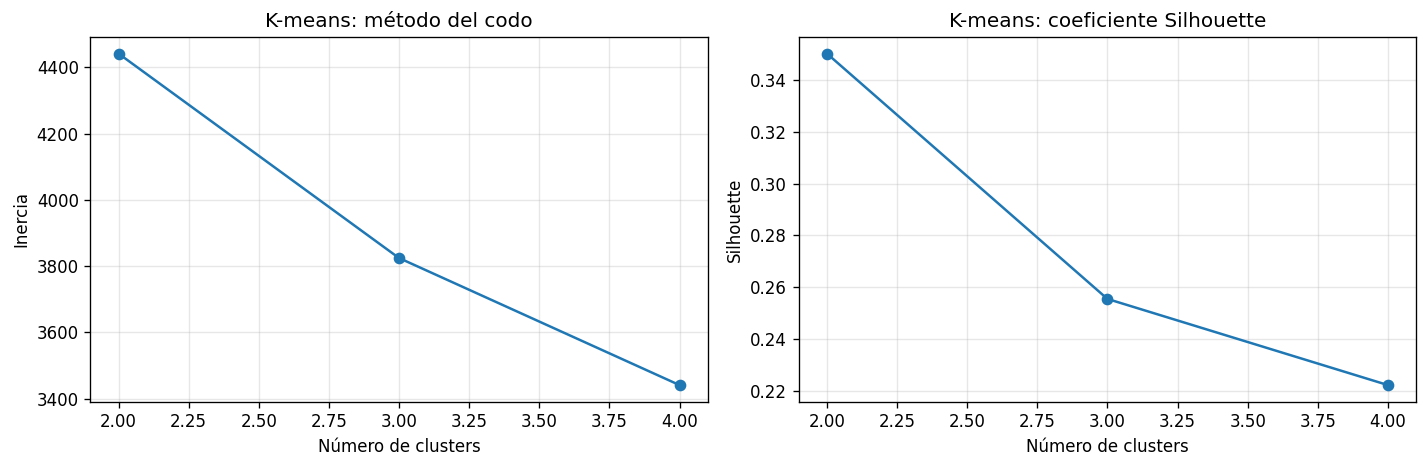

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(metricas["Clusters"], metricas["Inercia"], marker="o")
ejes[0].set(title="K-means: método del codo", xlabel="Número de clusters", ylabel="Inercia")
ejes[1].plot(metricas["Clusters"], metricas["Silhouette"], marker="o")
ejes[1].set(title="K-means: coeficiente Silhouette", xlabel="Número de clusters", ylabel="Silhouette")
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("resultados/01_metricas_kmeans.png", bbox_inches="tight")
plt.show()

In [ ]:
for k in [2, 3, 4]:
    print(f"K-means con {k} clusters")
    print("Tamaño de cada grupo:")
    display(df[f"Grupo_KMeans_{k}"].value_counts().sort_index().to_frame("Inmuebles"))
    print("Promedios de las variables numéricas:")
    display(df.groupby(f"Grupo_KMeans_{k}")[variables_numericas].mean().round(2))
    print("Distribución por localidad:")
    display(pd.crosstab(df[f"Grupo_KMeans_{k}"], df["Localidad"], normalize="index").round(3))
    print("Distribución por tipo de inmueble:")
    display(pd.crosstab(df[f"Grupo_KMeans_{k}"], df["Tipo_inmueble"], normalize="index").round(3))

K-means con 2 clusters
Tamaño de cada grupo:


,Inmuebles
Grupo_KMeans_2,
0,618
1,382


Promedios de las variables numéricas:


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato
Grupo_KMeans_2,,,,,,
0,1984490.07,60.98,1.83,1.47,8.52,2.98
1,6300711.57,154.56,4.01,1.49,8.35,5.53


Distribución por localidad:


...

,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato
Grupo_KMeans_4,,,,,,
0,2000101.25,61.25,1.83,1.0,8.56,2.99
1,6327014.21,154.35,4.06,2.0,8.37,5.54
2,6275222.41,154.76,3.96,1.0,8.34,5.52
3,1967061.15,60.68,1.83,2.0,8.48,2.98


Distribución por localidad:


Localidad,Chapinero,Suba,Usaquén
Grupo_KMeans_4,,,
0,0.344,0.350,0.307
1,0.282,0.314,0.404
2,0.325,0.309,0.366
3,0.360,0.346,0.295


Distribución por tipo de inmueble:


Tipo_inmueble,ApartaEstudio,Apto,Casa
Grupo_KMeans_4,,,
0,0.307,0.350,0.344
1,0.404,0.314,0.282
2,0.366,0.309,0.325
3,0.295,0.346,0.360


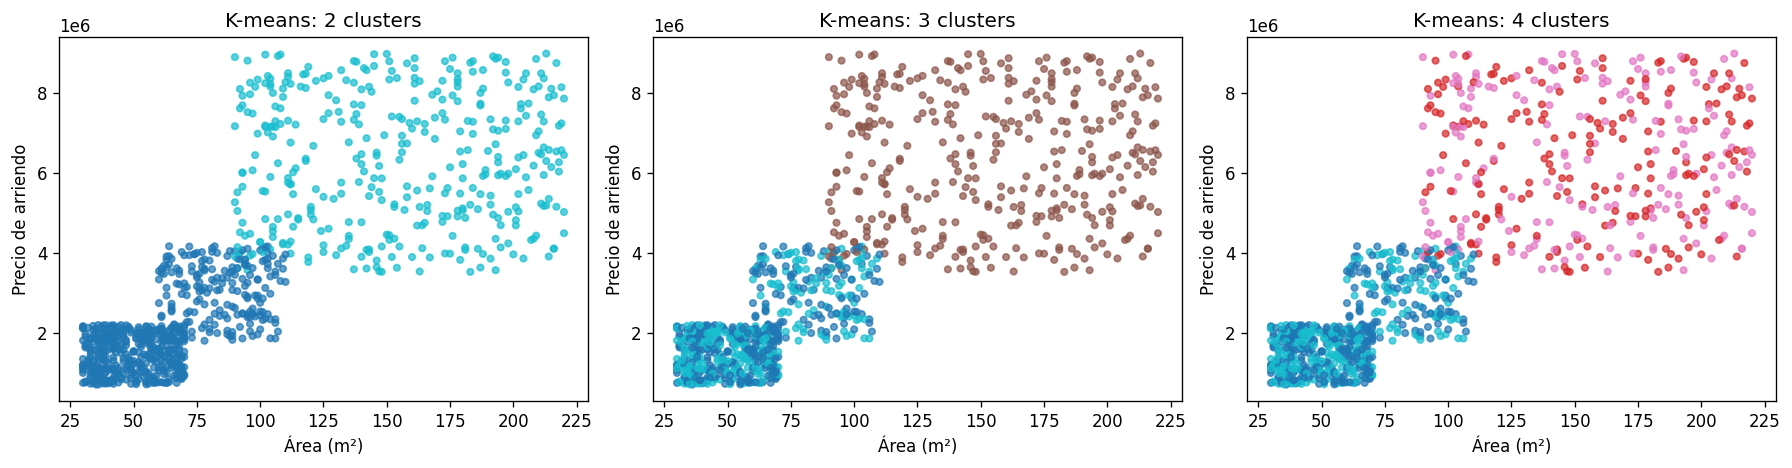

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, k in zip(ejes, [2, 3, 4]):
    eje.scatter(df["Area_m2"], df["Precio_arriendo"], c=etiquetas[k], cmap="tab10", s=15, alpha=0.7)
    eje.set(title=f"K-means: {k} clusters", xlabel="Área (m²)", ylabel="Precio de arriendo")
plt.tight_layout()
plt.savefig("resultados/02_clusters_area_precio.png", bbox_inches="tight")
plt.show()

Dimensiones preprocesadas: (1000, 12)
Dimensiones con PCA: (1000, 2)
Varianza explicada por componente: [0.46544 0.13749]
Varianza acumulada de los dos componentes: 0.60293


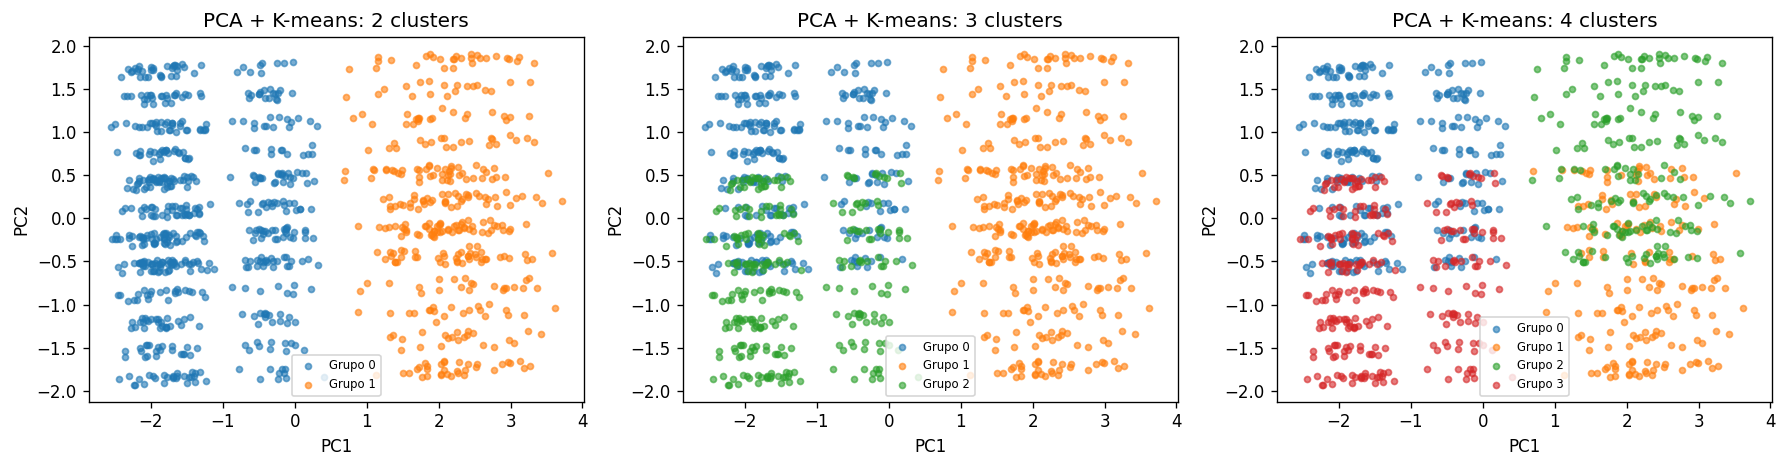

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preparado)
print("Dimensiones preprocesadas:", X_preparado.shape)
print("Dimensiones con PCA:", X_pca.shape)
print("Varianza explicada por componente:", np.round(pca.explained_variance_ratio_, 5))
print("Varianza acumulada de los dos componentes:", round(pca.explained_variance_ratio_.sum(), 5))
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, k in zip(ejes, [2, 3, 4]):
    for grupo in sorted(np.unique(etiquetas[k])):
        seleccion = etiquetas[k] == grupo
        eje.scatter(X_pca[seleccion, 0], X_pca[seleccion, 1], s=13, alpha=0.6, label=f"Grupo {grupo}")
    eje.set(title=f"PCA + K-means: {k} clusters", xlabel="PC1", ylabel="PC2")
    eje.legend(fontsize=7)
plt.tight_layout()
plt.savefig("resultados/03_pca_kmeans.png", bbox_inches="tight")
plt.show()

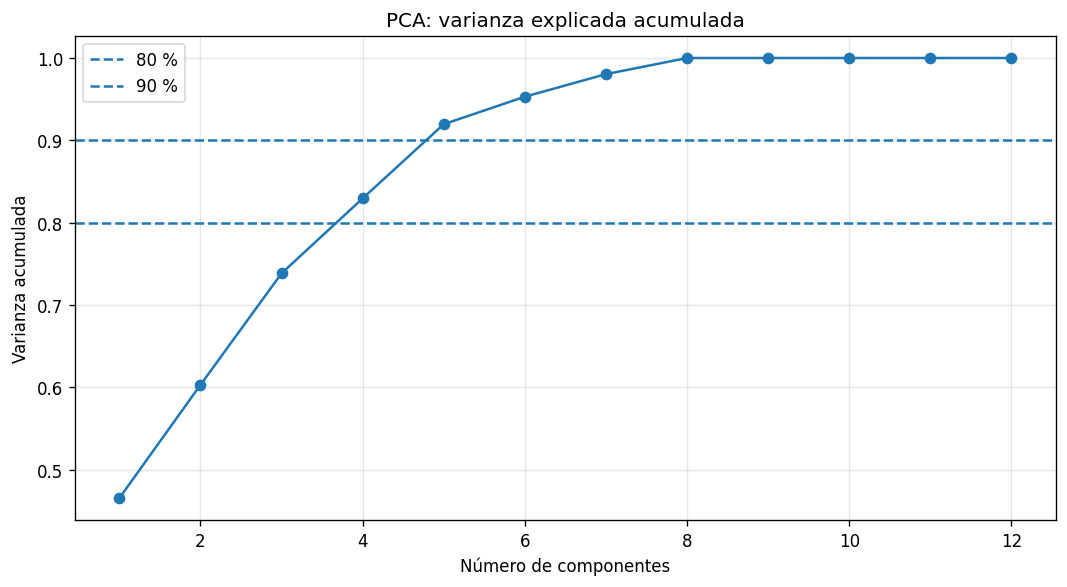

In [ ]:
pca_completo = PCA()
pca_completo.fit(X_preparado)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o")
plt.axhline(0.80, linestyle="--", label="80 %")
plt.axhline(0.90, linestyle="--", label="90 %")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("PCA: varianza explicada acumulada")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("resultados/04_varianza_pca.png", bbox_inches="tight")
plt.show()

In [ ]:
modelo_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos_pca = modelo_pca.fit_predict(X_pca)
df["Grupo_KMeans_PCA"] = grupos_pca
ari_pca = adjusted_rand_score(etiquetas[3], grupos_pca)
print("Adjusted Rand Index entre K-means original y K-means sobre PCA:", round(ari_pca, 5))
print("Tabla de correspondencia:")
display(pd.crosstab(df["Grupo_KMeans_3"], df["Grupo_KMeans_PCA"]))

Adjusted Rand Index entre K-means original y K-means sobre PCA: 0.67964
Tabla de correspondencia:


Grupo_KMeans_PCA,0,1,2
Grupo_KMeans_3,,,
0,240,0,86
1,0,382,0
2,68,0,224


Silhouette clustering jerárquico: 0.21934
Davies-Bouldin clustering jerárquico: 1.74313
ARI entre K-means y clustering jerárquico: 0.79452


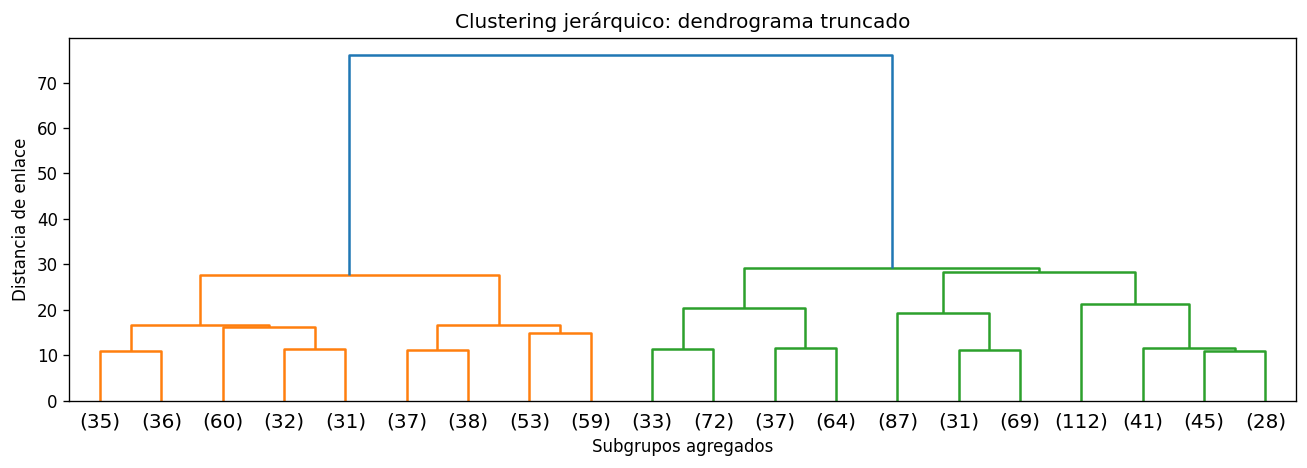

In [ ]:
jerarquico = AgglomerativeClustering(n_clusters=3, linkage="ward")
grupos_jerarquicos = jerarquico.fit_predict(X_preparado)
df["Grupo_Jerarquico_3"] = grupos_jerarquicos
silhouette_jerarquico = silhouette_score(X_preparado, grupos_jerarquicos)
davies_jerarquico = davies_bouldin_score(X_preparado, grupos_jerarquicos)
print("Silhouette clustering jerárquico:", round(silhouette_jerarquico, 5))
print("Davies-Bouldin clustering jerárquico:", round(davies_jerarquico, 5))
print("ARI entre K-means y clustering jerárquico:", round(adjusted_rand_score(etiquetas[3], grupos_jerarquicos), 5))
plt.figure(figsize=(11, 4))
dendrogram(linkage(X_preparado, method="ward"), truncate_mode="lastp", p=20)
plt.title("Clustering jerárquico: dendrograma truncado")
plt.xlabel("Subgrupos agregados")
plt.ylabel("Distancia de enlace")
plt.tight_layout()
plt.savefig("resultados/05_dendrograma.png", bbox_inches="tight")
plt.show()

Dimensiones después de SVD: (1000, 2)
Varianza explicada SVD: [0.46544 0.13749]
Varianza acumulada SVD: 0.60293


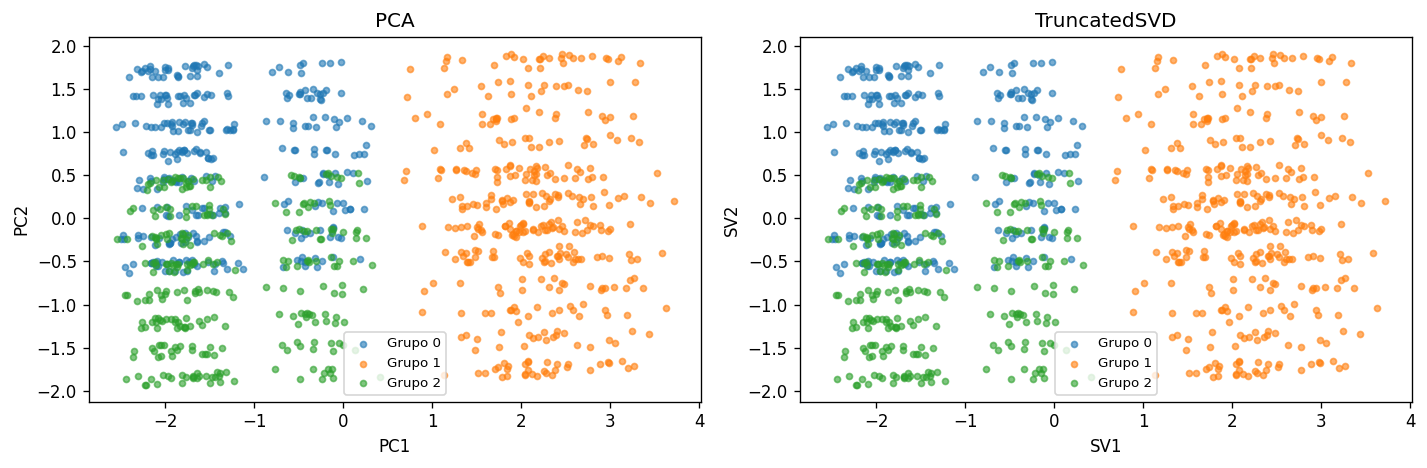

In [ ]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_preparado)
print("Dimensiones después de SVD:", X_svd.shape)
print("Varianza explicada SVD:", np.round(svd.explained_variance_ratio_, 5))
print("Varianza acumulada SVD:", round(svd.explained_variance_ratio_.sum(), 5))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for grupo in sorted(np.unique(etiquetas[3])):
    seleccion = etiquetas[3] == grupo
    ejes[0].scatter(X_pca[seleccion, 0], X_pca[seleccion, 1], s=13, alpha=0.6, label=f"Grupo {grupo}")
    ejes[1].scatter(X_svd[seleccion, 0], X_svd[seleccion, 1], s=13, alpha=0.6, label=f"Grupo {grupo}")
ejes[0].set(title="PCA", xlabel="PC1", ylabel="PC2")
ejes[1].set(title="TruncatedSVD", xlabel="SV1", ylabel="SV2")
for eje in ejes:
    eje.legend(fontsize=8)
plt.tight_layout()
plt.savefig("resultados/06_pca_svd.png", bbox_inches="tight")
plt.show()

In [ ]:
resumen = pd.concat([metricas, pd.DataFrame([{"Algoritmo": "Jerárquico Ward", "Clusters": 3, "Silhouette": silhouette_jerarquico, "Davies_Bouldin": davies_jerarquico, "Inercia": np.nan}])], ignore_index=True)
display(resumen.round(4))
resumen.to_csv("resultados/metricas.csv", index=False, encoding="utf-8-sig")
df.to_csv("resultados/inmuebles_segmentados.csv", index=False, encoding="utf-8-sig")
for k in [2, 3, 4]:
    df.groupby(f"Grupo_KMeans_{k}")[variables_numericas].agg(["count", "mean", "median"]).round(2).to_csv(f"resultados/perfiles_kmeans_{k}.csv", encoding="utf-8-sig")
with zipfile.ZipFile("resultados_modelos.zip", "w", zipfile.ZIP_DEFLATED) as archivo_zip:
    for carpeta, _, nombres in os.walk("resultados"):
        for nombre in nombres:
            ruta = os.path.join(carpeta, nombre)
            archivo_zip.write(ruta, arcname=ruta)
print("Resultados exportados en resultados_modelos.zip")

,Algoritmo,Clusters,Silhouette,Davies_Bouldin,Inercia
0,K-means,2,0.3503,1.2067,4441.9218
1,K-means,3,0.2555,1.5387,3824.4520
2,K-means,4,0.2222,1.8506,3440.6826
3,Jerárquico Ward,3,0.2193,1.7431,NaN


Resultados exportados en resultados_modelos.zip
